In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [3]:
setwd("/home/liuxuan/metadata/10-05/PRJNA759836/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,sample_description,Sample.Name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
1,SRR15698727,WGS,251,2640520,PRJNA759836,SAMN21197813,Metagenome or environmental,1394765,HEBREW UNIVERSITY OF JERUSALEM,Not Collected,⋯,unspecified,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-09-02T00:00:00Z,2021-09-02T10:48:00Z,1,C5_R2,806rcbc42_R2,SRP335366
2,SRR15698728,WGS,251,2071252,PRJNA759836,SAMN21197812,Metagenome or environmental,1146184,HEBREW UNIVERSITY OF JERUSALEM,Not Collected,⋯,unspecified,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-09-02T00:00:00Z,2021-09-02T10:48:00Z,1,Saliva_T24_R2,806rcbc41_R2,SRP335366
3,SRR15698729,WGS,251,2677919,PRJNA759836,SAMN21197811,Metagenome or environmental,1415119,HEBREW UNIVERSITY OF JERUSALEM,Not Collected,⋯,unspecified,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-09-02T00:00:00Z,2021-09-02T10:49:00Z,1,C24_R2,806rcbc40_R2,SRP335366
4,SRR15698730,WGS,251,3237398,PRJNA759836,SAMN21197810,Metagenome or environmental,1707602,HEBREW UNIVERSITY OF JERUSALEM,Not Collected,⋯,unspecified,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-09-02T00:00:00Z,2021-09-02T10:49:00Z,1,Saliva_T12_R2,806rcbc4_R2,SRP335366
5,SRR15698731,WGS,251,2372201,PRJNA759836,SAMN21197809,Metagenome or environmental,1268966,HEBREW UNIVERSITY OF JERUSALEM,Not Collected,⋯,unspecified,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-09-02T00:00:00Z,2021-09-02T10:49:00Z,1,Saliva_T33_R2,806rcbc39_R2,SRP335366
6,SRR15698732,WGS,251,1474876,PRJNA759836,SAMN21197808,Metagenome or environmental,806892,HEBREW UNIVERSITY OF JERUSALEM,Not Collected,⋯,unspecified,METAGENOMIC,human saliva metagenome,ILLUMINA,2021-09-02T00:00:00Z,2021-09-02T10:49:00Z,1,Saliva_T20_R2,806rcbc38_R2,SRP335366


[1] "Run"                    "Assay.Type"             "AvgSpotLen"            
 [4] "Bases"                  "BioProject"             "BioSample"             
 [7] "BioSampleModel"         "Bytes"                  "Center.Name"           
[10] "Collection_Date"        "Consent"                "DATASTORE.filetype"    
[13] "DATASTORE.provider"     "DATASTORE.region"       "Experiment"            
[16] "geographical_location"  "Instrument"             "isolation_source"      
[19] "latitude_and_longitude" "Library.Name"           "LibraryLayout"         
[22] "LibrarySelection"       "LibrarySource"          "Organism"              
[25] "Platform"               "ReleaseDate"            "create_date"           
[28] "version"                "sample_description"     "Sample.Name"           
[31] "SRA.Study"

In [5]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'sample_description',
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = 'V3-V4',
    Platform = initial_meta$Platform,
    Country = 'Israel',
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: ACTCCTACGGGAGGCAGCAG; R: GGACTACHVGGGTWTCTAAT',
    title = "Characterization of the Oral Microbiome Among Children With Type 1 Diabetes Compared With Healthy Children",
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [6]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 132
[1] 132


In [7]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA759836,SRR15698727,C5_R2,NA,NA,NA,V3-V4,ILLUMINA,Israel,saliva,2021-09-02T00:00:00Z,F: ACTCCTACGGGAGGCAGCAG; R: GGACTACHVGGGTWTCTAAT,Characterization of the Oral Microbiome Among Children With Type 1 Diabetes Compared With Healthy Children,YES,NA,NO
2,PRJNA759836,SRR15698728,Saliva_T24_R2,NA,NA,NA,V3-V4,ILLUMINA,Israel,saliva,2021-09-02T00:00:00Z,F: ACTCCTACGGGAGGCAGCAG; R: GGACTACHVGGGTWTCTAAT,Characterization of the Oral Microbiome Among Children With Type 1 Diabetes Compared With Healthy Children,YES,NA,NO
3,PRJNA759836,SRR15698729,C24_R2,NA,NA,NA,V3-V4,ILLUMINA,Israel,saliva,2021-09-02T00:00:00Z,F: ACTCCTACGGGAGGCAGCAG; R: GGACTACHVGGGTWTCTAAT,Characterization of the Oral Microbiome Among Children With Type 1 Diabetes Compared With Healthy Children,YES,NA,NO
4,PRJNA759836,SRR15698730,Saliva_T12_R2,NA,NA,NA,V3-V4,ILLUMINA,Israel,saliva,2021-09-02T00:00:00Z,F: ACTCCTACGGGAGGCAGCAG; R: GGACTACHVGGGTWTCTAAT,Characterization of the Oral Microbiome Among Children With Type 1 Diabetes Compared With Healthy Children,YES,NA,NO
5,PRJNA759836,SRR15698731,Saliva_T33_R2,NA,NA,NA,V3-V4,ILLUMINA,Israel,saliva,2021-09-02T00:00:00Z,F: ACTCCTACGGGAGGCAGCAG; R: GGACTACHVGGGTWTCTAAT,Characterization of the Oral Microbiome Among Children With Type 1 Diabetes Compared With Healthy Children,YES,NA,NO
6,PRJNA759836,SRR15698732,Saliva_T20_R2,NA,NA,NA,V3-V4,ILLUMINA,Israel,saliva,2021-09-02T00:00:00Z,F: ACTCCTACGGGAGGCAGCAG; R: GGACTACHVGGGTWTCTAAT,Characterization of the Oral Microbiome Among Children With Type 1 Diabetes Compared With Healthy Children,YES,NA,NO


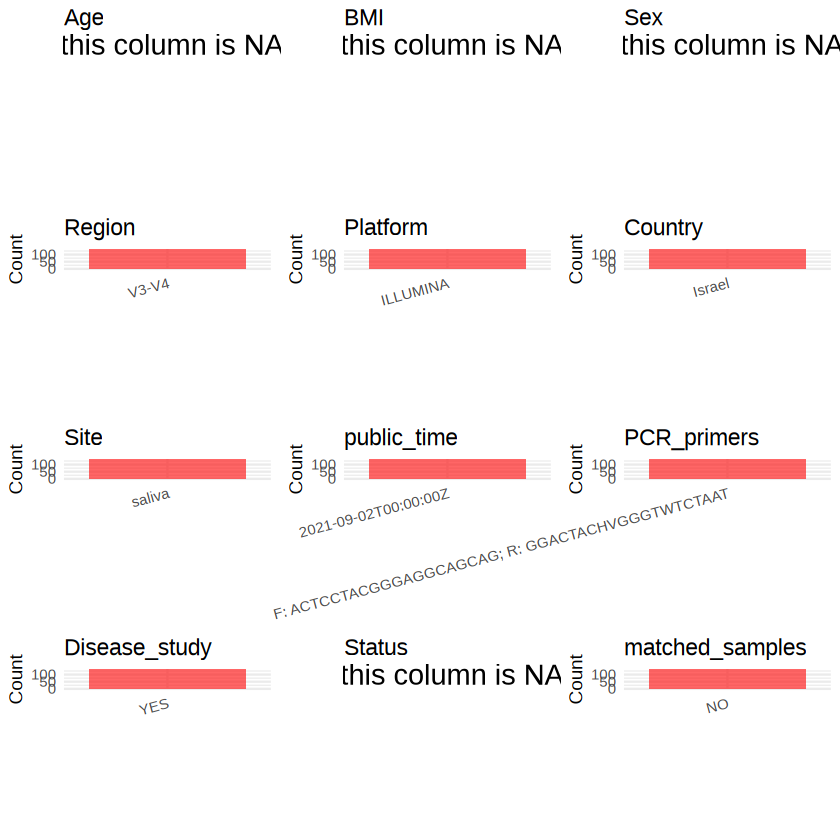

In [8]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [9]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA759836/metadata.csv", quote = T)